# RT-DETR: Baseline

У цьому експерименті ми навчали базову модель RT-DETR-L, метою було отримати початкові результати, з якими надалі
порівнюватимемо різні варіанти tuning.

Ми використовували pretrained модель \texttt{rtdetr-l.pt},
оптимізатор AdamW, learning rate $0.001$, batch size 2
та роздільність зображень $640 \times 640$.

Для оцінювання застосували 3-fold GroupKFold, розділяючи
дані за відеопослідовностями, щоб кадри одного відео
не потрапляли одночасно до train та validation.
Для оптимізації часу використовували кожен п'ятий
кадр для навчання та кожен другий для validation.
Кожен fold навчали протягом 6 епох.

Якість моделі оцінювали за допомогою COCOeval,
використовуючи pooled out-of-fold (OOF) predictions.
Основною метрикою обрали mAP@50:95, додатково
аналізували AP@50, результати для об'єктів різних
розмірів та приклади помилкових передбачень.


## 0. Середовище, файли та відтворюваність

In [ ]:
import os, sys, json, time, random, shutil, hashlib, subprocess, importlib.util
from pathlib import Path

for module, package in [("ultralytics", "ultralytics"), ("pycocotools", "pycocotools"), ("yaml", "pyyaml")]:
    if importlib.util.find_spec(module) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import torch, numpy as np, pandas as pd, yaml, ultralytics
from PIL import Image
from ultralytics import RTDETR
from tqdm.auto import tqdm

assert torch.cuda.is_available(), "Увімкніть GPU перед навчанням."
SEED=42
FOLDS=[0, 1, 2]
TRAIN_STEP=5
VAL_STEP=2
EPOCHS=6
BATCH_SIZE=2
IMG_SIZE=640
NUM_WORKERS=2
AMP=True
PATIENCE=100
EVAL_CONF=0.05
EVAL_BATCH=4
PRETRAINED_WEIGHTS_OVERRIDE=None
COMPETITION_SLUG='multiple-object-video-detection-hw-2-ucu-ai-2026'
NAMES=['person','bicycle','car','van','truck','tricycle','bus','motor']
USE_FAST_EVAL=False

print('Ultralytics:', ultralytics.__version__, 'Torch:',torch.__version__)
print('GPU:',torch.cuda.get_device_name(0))

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings
Ultralytics: 8.4.203 Torch: 2.11.0+cu130
GPU: Tesla T4


In [ ]:
DATA_ROOT_OVERRIDE='/kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026'
PREP_ROOT_OVERRIDE='/kaggle/input/datasets/olenadovbenchuk/preprocessed'
RUN_ROOT=Path('/kaggle/working/rtdetr_cv')
CACHE_ROOT=Path('/kaggle/working/rtdetr_fold_data')

def discover_data():
    if DATA_ROOT_OVERRIDE: return Path(DATA_ROOT_OVERRIDE)
    for p in [Path('/kaggle/input/competitions')/COMPETITION_SLUG,Path('/kaggle/input')/COMPETITION_SLUG]:
        if (p/'train'/'annotations_coco.json').exists(): return p
    for f in Path('/kaggle/input').rglob('annotations_coco.json'):
        if f.parent.name=='train' and (f.parent.parent/'val'/'annotations_coco.json').exists():
            return f.parent.parent
    raise FileNotFoundError('Не знайдено competition dataset. Додайте його через Add Input.')

def discover_prep():
    if PREP_ROOT_OVERRIDE: return Path(PREP_ROOT_OVERRIDE)
    for f in Path('/kaggle/input').rglob('folds.json'):
        if (f.parent/'train.json').exists() and (f.parent/'val.json').exists():
            return f.parent
    raise FileNotFoundError('Не знайдено preprocessing output: train.json, val.json, folds.json')

DATA_ROOT=discover_data(); PREP_ROOT=discover_prep()
RUN_ROOT.mkdir(parents=True,exist_ok=True);CACHE_ROOT.mkdir(parents=True,exist_ok=True)
print('Original images:',DATA_ROOT, '\nPreprocessed:',PREP_ROOT,'\nRun root:',RUN_ROOT)

Original images: /kaggle/input/competitions/multiple-object-video-detection-hw-2-ucu-ai-2026 
Preprocessed: /kaggle/input/datasets/olenadovbenchuk/preprocessed 
Run root: /kaggle/working/rtdetr_cv


## 1. Відтворюємо GroupKFold + sequence-level subsampling
Оригінальні image IDs, GT boxes та ignored regions беремо з preprocessing. Конвертація IDs класів 1–8 → 0–7 потрібна лише для Ultralytics YOLO labels. Файли YOLO labels формуються для кожного fold; symlinks на оригінальні images економлять місце.

In [ ]:
from collections import defaultdict

with (PREP_ROOT/'train.json').open() as f: TRAIN_RECORDS=json.load(f)
with (PREP_ROOT/'folds.json').open() as f: FOLD_MAP=json.load(f)
with (DATA_ROOT/'train'/'annotations_coco.json').open() as f: SOURCE_COCO=json.load(f)
META={int(x['id']):x for x in SOURCE_COCO['images']}
assert len(TRAIN_RECORDS)==len(FOLD_MAP)==24201, 'Потрібні повні preprocessing files з FRAME_STEP=1.'
assert set(int(x) for x in FOLD_MAP.values())=={0,1,2}

def seq_name(rec):
    return Path(str(rec['file_name']).replace('\\','/')).parent.name

def sample_by_sequence(records, step):
    seqs=defaultdict(list)
    for rec in records: seqs[seq_name(rec)].append(rec)
    return [rec for key in sorted(seqs) for rec in sorted(seqs[key],key=lambda x:x['file_name'])[::step]]

TRAIN_POOL=sample_by_sequence(TRAIN_RECORDS, TRAIN_STEP)
VAL_POOL=sample_by_sequence(TRAIN_RECORDS, VAL_STEP)

def fold_records(fold):
    tr=[r for r in TRAIN_POOL if int(FOLD_MAP[r['file_name']])!=fold]
    va=[r for r in VAL_POOL if int(FOLD_MAP[r['file_name']])==fold]
    assert tr and va
    assert {seq_name(r) for r in tr}.isdisjoint({seq_name(r) for r in va})
    assert {r['file_name'] for r in tr}.isdisjoint({r['file_name'] for r in va})
    return tr,va

for f in (0,1,2):
    tr,va=fold_records(f)
    print(f'Fold {f}: {len(tr):,} train / {len(va):,} OOF val, disjoint sequences OK')
print('Training pool:',len(TRAIN_POOL),'| OOF validation pool:',len(VAL_POOL))
object_counts=np.array([len(r['boxes']) for r in VAL_POOL])
print('Scene density on OOF validation: max=',object_counts.max(),
      '| median=',float(np.median(object_counts)),
      '| >300 objects=',int((object_counts>300).sum()),
      ' / ',len(object_counts))
print('Pretrained RT-DETR decoder uses 300 object queries; dense scenes may hit a recall ceiling.')

# У Faster R-CNN IDs: 1..8 (+0 background). У Ultralytics YOLO: 0..7.
def label_lines(rec):
    meta=META[int(rec['image_id'])]
    w,h=int(meta['width']),int(meta['height'])
    rows=[]
    assert len(rec['boxes'])==len(rec['labels'])
    for box, old_label in zip(rec['boxes'],rec['labels']):
        cid=int(old_label)-1
        assert 0<=cid<8, (rec['file_name'],cid)
        x1,y1,x2,y2=map(float,box)
        if not (x2>x1 and y2>y1): continue
        xc=((x1+x2)/2)/w; yc=((y1+y2)/2)/h
        bw=(x2-x1)/w; bh=(y2-y1)/h
        vals=[max(0.0,min(1.0,z)) for z in (xc,yc,bw,bh)]
        if vals[2] and vals[3]: rows.append(str(cid)+' '+' '.join(f'{v:.7f}' for v in vals))
    return rows

def _output_relative_filename(filename):
    """Remove the original COCO `images/` prefix before creating YOLO folders."""
    rel=Path(str(filename).replace('\\','/'))
    assert not rel.is_absolute() and '..' not in rel.parts, f'Unsafe image file name: {filename}'
    if rel.parts and rel.parts[0]=='images':
        rel=Path(*rel.parts[1:])
    assert rel.parts and 'images' not in rel.parts, f'Unexpected nested images/ directory: {filename}'
    return rel


def build_yolo_fold(fold):
    """Create standard YOLO image-label pairs. Rebuild automatically if layout is old."""
    from ultralytics.data.utils import img2label_paths

    root=CACHE_ROOT/f'fold_{fold}'
    tr,va=fold_records(fold)
    yaml_path=root/'data.yaml'
    marker=root/'.layout_v2_complete.json'
    settings={
        'layout_version':2,
        'fold':int(fold),
        'train_step':int(TRAIN_STEP),
        'val_step':int(VAL_STEP),
        'data_root':str(DATA_ROOT.resolve()),
        'folds_hash':hashlib.sha256((PREP_ROOT/'folds.json').read_bytes()).hexdigest(),
    }
    if marker.is_file() and yaml_path.is_file():
        try:
            if json.loads(marker.read_text())==settings:
                print(f'Fold {fold}: reusing verified YOLO dataset at {root}')
                return yaml_path
        except (ValueError, OSError):
            pass

    # Old layout contains images/train/images/... but labels/train/images/...
    # Ultralytics replaces the LAST /images/ component, so NONE of those labels are found.
    # Only remove temporary converted data, never original data or saved model checkpoints.
    if root.exists():
        shutil.rmtree(root)
    for split,records in [('train',tr),('val',va)]:
        nonempty=0
        for rec in tqdm(records,desc=f'YOLO labels {fold}/{split}',leave=False):
            original_rel=Path(str(rec['file_name']).replace('\\','/'))
            relative=_output_relative_filename(rec['file_name'])
            source=DATA_ROOT/'train'/original_rel
            assert source.is_file(),f'Missing source image: {source}'
            dest=root/'images'/split/relative
            dest.parent.mkdir(parents=True,exist_ok=True)
            dest.symlink_to(source.resolve())
            label=root/'labels'/split/relative.with_suffix('.txt')
            label.parent.mkdir(parents=True,exist_ok=True)
            lines=label_lines(rec)
            label.write_text('\n'.join(lines),encoding='utf-8')
            nonempty+=bool(lines)
            # Same lookup that Ultralytics applies internally.
            expected_label=Path(img2label_paths([str(dest)])[0])
            assert expected_label==label, (
                f'Ultralytics expects {expected_label}, but created {label}'
            )
        assert nonempty>0, f'Fold {fold}/{split} contains no nonempty annotation files'
        print(f'Fold {fold}/{split}: {len(records)} images, {nonempty} images with objects')
    config={'path':str(root.resolve()),'train':'images/train','val':'images/val',
            'nc':8,'names':dict(enumerate(NAMES))}
    yaml_path.write_text(yaml.safe_dump(config,sort_keys=False),encoding='utf8')
    marker.write_text(json.dumps(settings,indent=2),encoding='utf-8')
    return yaml_path

# Verify conversion with a concrete sample and no label-background class.
test_rec=TRAIN_POOL[0]
print('First record:',test_rec['file_name'],'| first YOLO labels:',label_lines(test_rec)[:2])

Fold 0: 3,243 train / 4,044 OOF val, disjoint sequences OK
Fold 1: 3,243 train / 4,046 OOF val, disjoint sequences OK
Fold 2: 3,250 train / 4,024 OOF val, disjoint sequences OK
Training pool: 4868 | OOF validation pool: 12114
Scene density on OOF validation: max= 161 | median= 43.0 | >300 objects= 0  /  12114
Pretrained RT-DETR decoder uses 300 object queries; dense scenes may hit a recall ceiling.
First record: images/uav0000013_00000_v/0000001.jpg | first YOLO labels: ['0 0.3284970 0.7764550 0.0260417 0.1164021', '0 0.3229167 0.7572751 0.0267857 0.1124339']


## 2. Навчання RT-DETR
Pretrained checkpoint для кожного fold. Кожен fold створює `best.pt`, `last.pt` і `results.csv` (mAP на validation після кожної епохи). Налаштування експерименту фіксуємо в config.json.

In [5]:
EXPERIMENT='baseline'
print("Variant:",EXPERIMENT)

Variant: baseline


In [ ]:
from pathlib import Path
import gc

# Tuning ONLY is enabled via the model-specific trainer class for Colab.
CUSTOM_DENOISING=None
if EXPERIMENT=='denoising':
    from ultralytics.models.rtdetr.train import RTDETRTrainer
    class CustomDenoisingTrainer(RTDETRTrainer):
        def get_model(self, cfg=None, weights=None, verbose=True):
            model=super().get_model(cfg,weights,verbose)
            head=model.model[-1]
            assert hasattr(head,'num_denoising') and hasattr(head,'label_noise_ratio'), 'Ultralytics RTDETRDecoder API changed'
            print('Denoising BEFORE:', head.num_denoising,head.label_noise_ratio,head.box_noise_scale)
            head.num_denoising=50
            print('Denoising AFTER:',head.num_denoising,head.label_noise_ratio,head.box_noise_scale)
            return model
    CUSTOM_DENOISING=CustomDenoisingTrainer

LR = {'baseline':0.001, 'lr_tuning':0.0003,'denoising':0.001}[EXPERIMENT]
RUN_NAME={'baseline':'rtdetr_baseline','lr_tuning':'rtdetr_lr_0003','denoising':'rtdetr_denoising_50'}[EXPERIMENT]
RUN_DIR=RUN_ROOT/RUN_NAME
RUN_DIR.mkdir(parents=True,exist_ok=True)

config={
    'experiment':EXPERIMENT,'run':RUN_NAME,'train_step':TRAIN_STEP,'val_step':VAL_STEP,
    'folds_definition_sha256':hashlib.sha256((PREP_ROOT/'folds.json').read_bytes()).hexdigest(),
    'train_files_sha256':hashlib.sha256(json.dumps([r['file_name'] for r in TRAIN_POOL]).encode()).hexdigest(),
    'val_files_sha256':hashlib.sha256(json.dumps([r['file_name'] for r in VAL_POOL]).encode()).hexdigest(),
    'epochs':EPOCHS,'batch':BATCH_SIZE,'imgsz':IMG_SIZE,'seed':SEED,'lr0':LR,
    'model':'rtdetr-l.pt','num_classes':8,'num_queries':300,
    'denoising_queries':50 if EXPERIMENT=='denoising' else 100,
    'amp':AMP,'optimizer':'AdamW','mosaic':0.0,'mixup':0.0,
    'val_method':'YOLO per epoch; COCO OOF after all training with ignored-crowd approximation',
    'ultralytics_version':ultralytics.__version__,
}
config_path=RUN_DIR/'config.json'
if config_path.is_file():
    old=json.loads(config_path.read_text())
    assert old==config,'RUN_NAME конфліктує з попередньою конфігурацією. Обери нову назву.'
else: config_path.write_text(json.dumps(config,indent=2,ensure_ascii=False))
print('Experiment config:',json.dumps(config,indent=2))


def weights_path():
    if PRETRAINED_WEIGHTS_OVERRIDE is not None:
        path=Path(PRETRAINED_WEIGHTS_OVERRIDE)
        assert path.is_file(),f'Pretrained file missing: {path}'
        return str(path)
    return 'rtdetr-l.pt'


def train_one_fold(fold):
    fold_dir=RUN_DIR/f'fold_{fold}'
    if (fold_dir/'fold_result.json').is_file():
        print(f'Fold {fold}: COCO evaluation completed; skipping training.')
        return
    best_saved=fold_dir/'weights'/'best.pt'
    done_file=fold_dir/'training_done.json'
    results_csv=fold_dir/'results.csv'
    if best_saved.is_file() and done_file.is_file():
        print(f'Fold {fold}: training is complete; only COCO evaluation remains.')
        return
    if best_saved.is_file() and results_csv.is_file():
        historic=pd.read_csv(results_csv)
        if len(historic)>=EPOCHS:
            print(f'Fold {fold}: all {EPOCHS} epochs found in results.csv; do not resume a completed run.')
            return
    yaml_path=build_yolo_fold(fold)
    (fold_dir).mkdir(parents=True,exist_ok=True)
    pretrained=weights_path()
    latest=fold_dir/'weights'/'last.pt'
    if latest.is_file():
        print('Resuming saved fold',fold,'from',latest)
        model=RTDETR(str(latest))
        resume=True
    else:
        model=RTDETR(pretrained)
        resume=False
    print('Starting fold',fold, '| learning rate',LR,'| resume',resume)
    train_args=dict(
        data=str(yaml_path),epochs=EPOCHS,batch=BATCH_SIZE,imgsz=IMG_SIZE,
        device=0,workers=NUM_WORKERS,seed=SEED+fold,deterministic=False,
        project=str(RUN_DIR),name=f'fold_{fold}',exist_ok=True,
        pretrained=True,optimizer='AdamW',lr0=LR,lrf=0.1,
        amp=AMP,patience=PATIENCE,save=True,save_period=-1,plots=False,
        val=True,mosaic=0.0,mixup=0.0,copy_paste=0.0,
        fliplr=0.5,flipud=0.0, degrees=0.0,translate=0.0,scale=0.0,
        cache=False,verbose=True,resume=resume,
    )
    if CUSTOM_DENOISING is not None: train_args['trainer']=CUSTOM_DENOISING
    started=time.perf_counter()
    model.train(**train_args)
    elapsed=time.perf_counter()-started
    # If training done, best is used for COCO evaluation
    best=fold_dir/'weights'/'best.pt'
    last=fold_dir/'weights'/'last.pt'
    assert best.exists() or last.exists(),f'No checkpoint saved for fold {fold}: {fold_dir}'
    (fold_dir/'training_done.json').write_text(json.dumps({
        'fold':fold,'best_weights':str(best if best.exists() else last),
        'last_weights':str(last),'seconds_train_and_native_validation':elapsed,
        'complete':True},indent=2))
    del model
    gc.collect();torch.cuda.empty_cache()
    print('Fold',fold,'TRAINING DONE. Checkpoint:',best if best.exists() else last)

for fold in FOLDS:
    train_one_fold(fold)

Experiment config: {
  "experiment": "baseline",
  "run": "rtdetr_baseline",
  "train_step": 5,
  "val_step": 2,
  "folds_definition_sha256": "36e128263142d18ff3b8e321e7f7b379a54e3bc0f1e25dfa2beacf85b67b2713",
  "train_files_sha256": "b0eef6c9dc3673734906c5c95d4b9b3b7e0838564ec603c7ea7619d958cf32d3",
  "val_files_sha256": "fde4a07ff504cec93f9f4ac58fef1a93590e6d029e8ce0a8e3b57d8ac518a733",
  "epochs": 6,
  "batch": 2,
  "imgsz": 640,
  "seed": 42,
  "lr0": 0.001,
  "model": "rtdetr-l.pt",
  "num_classes": 8,
  "num_queries": 300,
  "denoising_queries": 100,
  "amp": true,
  "optimizer": "AdamW",
  "mosaic": 0.0,
  "mixup": 0.0,
  "val_method": "YOLO per epoch; COCO OOF after all training with ignored-crowd approximation",
  "ultralytics_version": "8.4.203"
}


YOLO labels 0/train:   0%|          | 0/3243 [00:00<?, ?it/s]

Fold 0/train: 3243 images, 3243 images with objects


YOLO labels 0/val:   0%|          | 0/4044 [00:00<?, ?it/s]

Fold 0/val: 4044 images, 4042 images with objects
Starting fold 0 | learning rate 0.001 | resume False
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rtdetr_fold_data/fold_0/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=

/usr/local/lib/python3.13/dist-packages/ray/train/_internal/session.py:683: UserWarning: `get_trial_id` is meant to only be called inside a function that is executed by a Tuner or Trainer. Returning `None`.
  warnings.warn(


... (5 outputs left out)

YOLO labels 2/train:   0%|          | 0/3250 [00:00<?, ?it/s]

Fold 2/train: 3250 images, 3250 images with objects


YOLO labels 2/val:   0%|          | 0/4024 [00:00<?, ?it/s]

Fold 2/val: 4024 images, 4024 images with objects
Starting fold 2 | learning rate 0.001 | resume False
Ultralytics 8.4.203 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14912MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=2, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/kaggle/working/rtdetr_fold_data/fold_2/data.yaml, degrees=0.0, deterministic=False, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=6, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.001, lrf=0.1, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=

## 3. Незалежна COCO-оцінка (OOF)
Усі predictions повертаємо до оригінальних координат. Використовуємо однакові category IDs, COCO maxDets=100 та однакову обробку ignored GT, що в Faster R-CNN. Окремо рахуються inference ms/image і AP_small.

In [ ]:
from pycocotools.coco import COCO
from pycocotools.cocoeval import COCOeval
import io,contextlib

def xywh(box):
    x1,y1,x2,y2=map(float,box)
    return [x1,y1,max(0.,x2-x1),max(0.,y2-y1)]

def gt_for_fold(records):
    images=[]; anns=[]
    for r in records:
        im=META[int(r['image_id'])]
        images.append({'id':int(r['image_id']),'width':int(im['width']),'height':int(im['height'])})
        for box,cid in zip(r['boxes'],r['labels']):
            b=xywh(box)
            anns.append({'id':len(anns)+1,'image_id':int(r['image_id']),
                         'category_id':int(cid),'bbox':b,'area':b[2]*b[3], 'iscrowd':0})
        for box in r['ignored_boxes']:
            b=xywh(box)
            for cid in range(1,9):
                anns.append({'id':len(anns)+1,'image_id':int(r['image_id']),
                             'category_id':cid,'bbox':b,'area':b[2]*b[3],'iscrowd':1,'ignore':1})
    return {'images':images,'annotations':anns,
            'categories':[{'id':i,'name':NAMES[i-1]} for i in range(1,9)]}

def coco_eval(gt, preds):
    coco=COCO();coco.dataset=gt
    with contextlib.redirect_stdout(io.StringIO()): coco.createIndex()
    if preds:
        with contextlib.redirect_stdout(io.StringIO()): det=coco.loadRes(preds)
    else:
        det=COCO();det.dataset={'images':gt['images'],'annotations':[],'categories':gt['categories']}
        with contextlib.redirect_stdout(io.StringIO()): det.createIndex()
    ev=COCOeval(coco,det,'bbox')
    ev.params.imgIds=[i['id'] for i in gt['images']]
    ev.params.catIds=list(range(1,9))
    with contextlib.redirect_stdout(io.StringIO()): ev.evaluate();ev.accumulate();ev.summarize()
    return {'mAP':float(ev.stats[0]),'AP50':float(ev.stats[1]),'AP_small':float(ev.stats[3]),
            'AP_medium':float(ev.stats[4]),'AP_large':float(ev.stats[5])}

def evaluate_one_fold(fold):
    fold_dir=RUN_DIR/f'fold_{fold}'
    path=fold_dir/'fold_result.json'
    if path.is_file():
        print('COCO evaluation fold',fold,'already exists; skipping.')
        return
    _,records=fold_records(fold)
    weights=fold_dir/'weights'/'best.pt'
    if not weights.exists(): weights=fold_dir/'weights'/'last.pt'
    assert weights.is_file(),'Train this fold before evaluating.'
    model=RTDETR(str(weights))
    preds=[];inference_s=0.;inference_n=0
    for i in tqdm(range(0,len(records),EVAL_BATCH),desc=f'COCO fold {fold}'):
        bunch=records[i:i+EVAL_BATCH]
        paths=[str(DATA_ROOT/'train'/str(r['file_name']).replace('\\','/')) for r in bunch]
        results=model.predict(source=paths,imgsz=IMG_SIZE,device=0,
                              conf=EVAL_CONF,max_det=300,verbose=False,quantize=16 if AMP else 32,
                              stream=False)
        assert len(results)==len(bunch)
        for r,res in zip(bunch,results):
            if res.boxes is None: continue
            if res.speed and 'inference' in res.speed:
                inference_s+=float(res.speed['inference'])/1000.
                inference_n+=1
            for box,cls,score in zip(res.boxes.xyxy.cpu().tolist(),
                                     res.boxes.cls.cpu().tolist(),
                                     res.boxes.conf.cpu().tolist()):
                preds.append({'image_id':int(r['image_id']),
                              'category_id':int(cls)+1,'bbox':xywh(box),'score':float(score)})
    gt=gt_for_fold(records)
    stats=coco_eval(gt,preds)
    stats['ms_per_image']=1000*inference_s/max(inference_n,1)
    stats['frames']=len(records)
    tmp=path.with_suffix('.tmp')
    tmp.write_text(json.dumps({'fold':fold,'metrics':stats,'ground_truth':gt,
                               'predictions':preds,'n_train':len(fold_records(fold)[0]),
                               'n_val':len(records)}))
    tmp.replace(path)
    del model
    gc.collect();torch.cuda.empty_cache()
    print('Fold',fold,stats)

for fold in FOLDS:
    evaluate_one_fold(fold)

COCO evaluation fold 0 already exists; skipping.
COCO evaluation fold 1 already exists; skipping.


COCO fold 2:   0%|          | 0/1006 [00:00<?, ?it/s]

Fold 2 {'mAP': 0.039163127051638706, 'AP50': 0.08445616683191223, 'AP_small': 0.016189765217637937, 'AP_medium': 0.03908089825560358, 'AP_large': 0.1244141641801457, 'ms_per_image': 20.5681385755463, 'frames': 4024}


## 4. Підсумкова 3-fold OOF таблиця
Підсумкова pooled OOF mAP — це одна COCOeval на всіх out-of-fold predictions.

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd

fold_paths=[RUN_DIR/f'fold_{f}'/'fold_result.json' for f in (0,1,2)]
if all(x.is_file() for x in fold_paths):
    results=[json.loads(x.read_text()) for x in fold_paths]
    gt={'images':[], 'annotations':[], 'categories':results[0]['ground_truth']['categories']}
    preds=[];rows=[]
    for x in results:
        rows.append({'fold':x['fold'],'n_train':x['n_train'],'n_val':x['n_val'],**x['metrics']})
        gt['images'] += x['ground_truth']['images']
        for ann in x['ground_truth']['annotations']:
            ann=dict(ann);ann['id']=len(gt['annotations'])+1;gt['annotations'].append(ann)
        preds += x['predictions']
    assert len({i['id'] for i in gt['images']})==len(gt['images'])==len(VAL_POOL)
    metrics=coco_eval(gt,preds)
    df=pd.DataFrame(rows);df.to_csv(RUN_DIR/'fold_metrics.csv',index=False)
    (RUN_DIR/'oof_predictions.json').write_text(json.dumps(preds))
    (RUN_DIR/'oof_ground_truth.json').write_text(json.dumps(gt))
    summary={'run':RUN_NAME,'experiment':EXPERIMENT,'n_oof_frames':len(gt['images']),
             'oof_metrics':metrics,'fold_mean_mAP':float(df['mAP'].mean()),
             'mean_ms_per_image':float(df['ms_per_image'].mean()),'config':config}
    (RUN_DIR/'summary.json').write_text(json.dumps(summary,indent=2))
    print('POOLED OOF:',metrics)
    display(df)
else:
    print('Partial run: first complete and evaluate all 3 folds before pooled OOF.')

POOLED OOF: {'mAP': 0.11999453734405321, 'AP50': 0.23423808181246192, 'AP_small': 0.02716556888016201, 'AP_medium': 0.10058807341446402, 'AP_large': 0.25918807849594916}


,fold,n_train,n_val,mAP,AP50,AP_small,AP_medium,AP_large,ms_per_image,frames
0,0,3243,4044,0.192297,0.359596,0.075816,0.134784,0.295153,21.058358,4044
1,1,3243,4046,0.134369,0.268612,0.028233,0.132439,0.321439,20.807178,4046
2,2,3250,4024,0.039163,0.084456,0.016190,0.039081,0.124414,20.568139,4024


## 5. Validation mAP curves та CNN comparison
Для RT-DETR є `results.csv` після кожної епохи. Старий CNN baseline вимірював mAP лише наприкінці: з нього можна чесно порівняти final OOF, але не намалювати повну CNN-криву без нової per-epoch CNN evaluation.

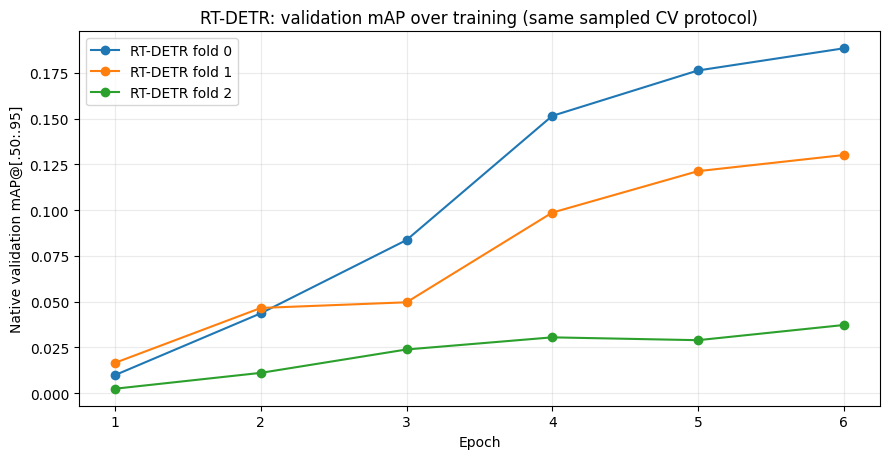

CNN curve not available: old Faster R-CNN notebook evaluated COCO only after epoch 6.
To fully meet the rubric, run per-epoch CNN validation on the same folds/budget.


In [ ]:
fig,ax=plt.subplots(figsize=(9,4.7))
plotted=False
for fold in (0,1,2):
    csv=RUN_DIR/f'fold_{fold}'/'results.csv'
    if not csv.exists(): continue
    d=pd.read_csv(csv);d.columns=d.columns.str.strip()
    ycols=[c for c in d if 'mAP50-95' in c and '(B)' in c]
    if not ycols:
        print('No mAP column in',csv,':',list(d.columns))
        continue
    x=d['epoch'] if 'epoch' in d else np.arange(1,len(d)+1)
    ax.plot(x,d[ycols[0]],marker='o',label=f'RT-DETR fold {fold}')
    plotted=True
ax.set(xlabel='Epoch',ylabel='Native validation mAP@[.50:.95]',
       title='RT-DETR: validation mAP over training (same sampled CV protocol)')
ax.grid(alpha=.25)
if plotted:
    ax.legend();fig.tight_layout()
    fig.savefig(RUN_DIR/'rtdetr_val_map_curves.png',dpi=160)
    plt.show()
else:
    plt.close(fig);print('No completed results.csv yet')

# Вимога про CNN-based detector: Faster R-CNN baseline рахує mAP тільки в КІНЦІ fold.
# Для двох кривих потрібен окремий CNN validation_mAP_per_epoch.csv з per-epoch COCO evaluation.
# CNN OOF final mAP можна зіставити з RT-DETR final OOF mAP у таблиці/діаграмі нижче.
CNN_SUMMARY_PATH = None
CNN_CURVE_CSV = None    # CSV із колонками epoch, mAP 
if CNN_CURVE_CSV and Path(CNN_CURVE_CSV).exists():
    d=pd.read_csv(CNN_CURVE_CSV)
    assert {'epoch','mAP'}<=set(d.columns)
    fig,ax=plt.subplots(figsize=(7,4));ax.plot(d.epoch,d.mAP,marker='o',label='Faster R-CNN')
    ax.set(xlabel='Epoch',ylabel='COCO mAP',title='CNN reference curve (same metric/protocol)')
    ax.legend();ax.grid(alpha=.3);plt.show()
else:
    print('CNN curve not available: old Faster R-CNN notebook evaluated COCO only after epoch 6.')
    print('To fully meet the rubric, run per-epoch CNN validation on the same folds/budget.')

if CNN_SUMMARY_PATH and Path(CNN_SUMMARY_PATH).exists() and (RUN_DIR/'summary.json').exists():
    cnn=json.loads(Path(CNN_SUMMARY_PATH).read_text())['oof_metrics']['mAP']
    rt=json.loads((RUN_DIR/'summary.json').read_text())['oof_metrics']['mAP']
    display(pd.DataFrame([{'model':'Faster R-CNN','pooled_OOF_mAP':cnn},
                          {'model':'RT-DETR','pooled_OOF_mAP':rt}]))

## 6. Failure cases
Зелені boxes — GT, червоні — prediction.

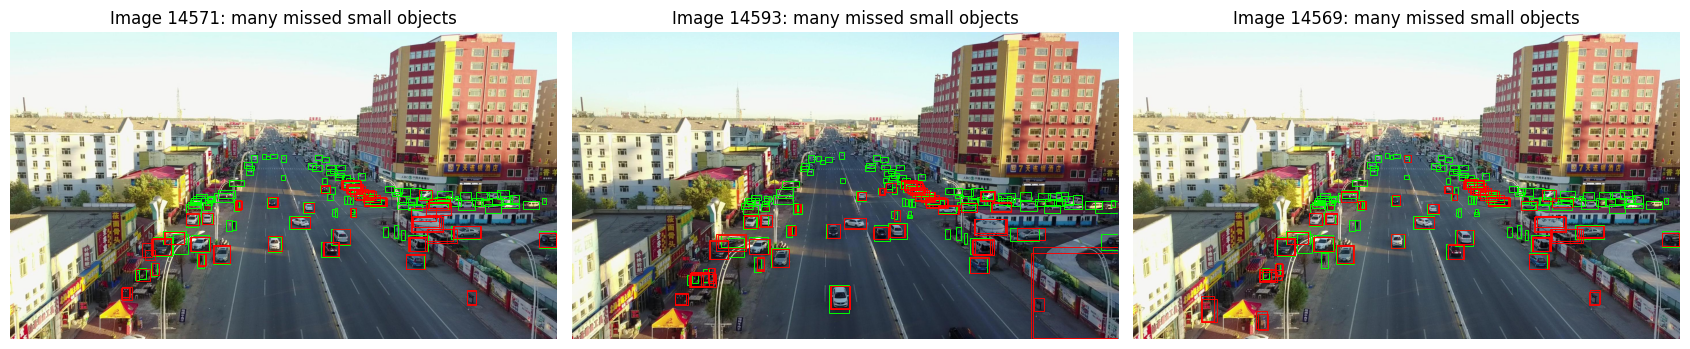

Green=GT, red=predictions; visually analyze at least three cases in your own report.


In [11]:
# Знайти 3 failure cases: кількість пропущених small GT та FP (груба діагностика).
# Візуалізуємо boxes на зображеннях. Ignored regions не враховувати як звичайні FP.
from matplotlib.patches import Rectangle

def iou_xywh(a,b):
    ax1,ay1,aw,ah=a;bx1,by1,bw,bh=b
    xx1=max(ax1,bx1);yy1=max(ay1,by1)
    xx2=min(ax1+aw,bx1+bw);yy2=min(ay1+ah,by1+bh)
    it=max(0.,xx2-xx1)*max(0.,yy2-yy1)
    return it/max(aw*ah+bw*bh-it,1e-9)

if (RUN_DIR/'oof_predictions.json').exists():
    preds=json.loads((RUN_DIR/'oof_predictions.json').read_text())
    gt=json.loads((RUN_DIR/'oof_ground_truth.json').read_text())
    pp=defaultdict(list);aa=defaultdict(list)
    for p in preds:
        if p['score']>=0.25: pp[p['image_id']].append(p)
    for a in gt['annotations']:
        if not a['iscrowd']: aa[a['image_id']].append(a)
    ranks=[]
    for im in gt['images']:
        ident=im['id']; small=[a for a in aa[ident] if a['area']<32*32]
        misses=sum(not any(p['category_id']==a['category_id'] and iou_xywh(a['bbox'],p['bbox'])>=.5 for p in pp[ident]) for a in small)
        ranks.append((misses,ident))
    top=sorted(ranks,reverse=True)[:3]
    by_id={int(r['image_id']):r for r in TRAIN_RECORDS}
    fig,axs=plt.subplots(1,len(top),figsize=(17,5))
    if len(top)==1: axs=[axs]
    for ax,(_,ident) in zip(axs,top):
        rec=by_id[ident]
        img=Image.open(DATA_ROOT/'train'/str(rec['file_name']).replace('\\','/')).convert('RGB')
        ax.imshow(img);ax.set_title(f'Image {ident}: many missed small objects');ax.axis('off')
        for a in aa[ident]:
            x,y,w,h=a['bbox'];ax.add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='lime',linewidth=.7))
        for p in pp[ident][:100]:
            x,y,w,h=p['bbox'];ax.add_patch(Rectangle((x,y),w,h,fill=False,edgecolor='red',linewidth=.65))
    fig.tight_layout();fig.savefig(RUN_DIR/'failure_cases.png',dpi=140);plt.show()
    print('Green=GT, red=predictions; visually analyze at least three cases in your own report.')
else:
    print('Run all 3-fold OOF evaluation before plotting failure cases.')

### Висновки

У результаті baseline експерименту отримали
pooled OOF mAP@50:95 = 0.1200 та AP@50 = 0.2342.

Результати суттєво відрізнялися між folds:
0.1923, 0.1344 та 0.0392 відповідно.
Найнижчу якість модель показала на fold 2,
що вказує на складність узагальнення для окремих
відеопослідовностей. Найбільші труднощі виникали з малими об'єктами:
AP_small = 0.0272 порівняно з AP_large = 0.2592.
Візуальний аналіз також показав пропущені об'єкти
та можливі хибні детекції. Отримані результати використовуємо як baseline
для подальших експериментів із tuning гіперпараметрів.
